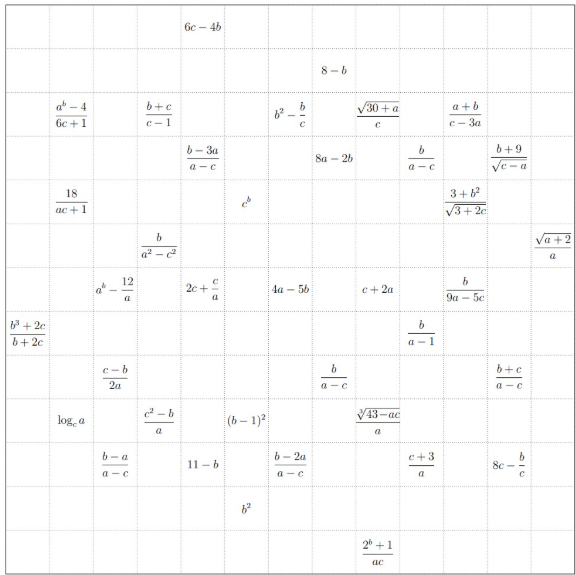

In [1]:
import numpy as np

We create a grid with all formulas inside

In [2]:
# Initializing a 13x13 grid
grid = [[None for _ in range(13)] for _ in range(13)]

# Row 0
grid[0][4] = lambda a, b, c: 6*c - 4*b

# Row 1
grid[1][7] = lambda a, b, c: 8 - b

# Row 2
grid[2][1] = lambda a, b, c: (a**b - 4) / (6*c + 1)
grid[2][3] = lambda a, b, c: (b + c) / (c - 1)
grid[2][6] = lambda a, b, c: b**2 - (b / c)
grid[2][8] = lambda a, b, c: (30 + a)**0.5 / c
grid[2][10] = lambda a, b, c: (a + b) / (c - 3*a)

# Row 3
grid[3][4] = lambda a, b, c: (b - 3*a) / (a - c)
grid[3][7] = lambda a, b, c: 8*a - 2*b
grid[3][9] = lambda a, b, c: b / (a - c)
grid[3][11] = lambda a, b, c: (b + 9) / (c - a)**0.5

# Row 4
grid[4][1] = lambda a, b, c: 18 / (a*c + 1)
grid[4][5] = lambda a, b, c: c**b
grid[4][10] = lambda a, b, c: (3 + b**2) / (3 + 2*c)**0.5

# Row 5
grid[5][3] = lambda a, b, c: b / (a**2 - c**2)
grid[5][12] = lambda a, b, c: (a + 2)**0.5 / a

# Row 6
grid[6][2] = lambda a, b, c: a**b - (12 / a)
grid[6][4] = lambda a, b, c: 2*c + (c / a)
grid[6][6] = lambda a, b, c: 4*a - 5*b
grid[6][8] = lambda a, b, c: c + 2*a
grid[6][10] = lambda a, b, c: b / (9*a - 5*c)

# Row 7
grid[7][0] = lambda a, b, c: (b**3 + 2*c) / (b + 2*c)
grid[7][9] = lambda a, b, c: b / (a - 1)

# Row 8
grid[8][2] = lambda a, b, c: (c - b) / (2*a)
grid[8][7] = lambda a, b, c: b / (a - c)
grid[8][11] = lambda a, b, c: (b + c) / (a - c)

# Row 9
grid[9][1] = lambda a, b, c: np.log(a) / np.log(c)
grid[9][3] = lambda a, b, c: (c**2 - b) / a
grid[9][5] = lambda a, b, c: (b - 1)**2
grid[9][8] = lambda a, b, c: (43 - a*c)**(1/3) / a

# Row 10
grid[10][2] = lambda a, b, c: (b - a) / (a - c)
grid[10][4] = lambda a, b, c: 11 - b
grid[10][6] = lambda a, b, c: (b - 2*a) / (a - c)
grid[10][9] = lambda a, b, c: (c + 3) / a
grid[10][11] = lambda a, b, c: 8*c - (b / c)

# Row 11
grid[11][5] = lambda a, b, c: b**2

# Row 12
grid[12][8] = lambda a, b, c: (2**b + 1) / (a * c)

We also define a list with just the formulas

In [3]:
all_formulas = [cell for row in grid for cell in row if cell is not None]

The grid is 13x13, so there is only a limited amount of K-omino pieces that can fit inside. From this we can determine K, the highest integer that can possibly result from the formulas. To find the upperbound of K we simply check the cumulative sum untill $13*13=169$

In [4]:
sum = 0
k = 1

while sum + k <= 13 * 13:
    sum += k
    k += 1

print(f"Biggest piece possible: {k}")

Biggest piece possible: 18


We know each formula must result in a value in $K \in [1, 18]$

Now we pick a few interesting formulas from the grid to reverse engineer them, to be exact:

$\frac{\sqrt{a+2}}{a} = K \rightarrow a = \frac{1 + \sqrt{1 + 8K^2}}{2K^2}$

$8 - b = K \rightarrow b = 8 - K$

From these we can compute all possible values for a and b:


In [5]:


a = lambda k: (1 + np.sqrt(1 + 8*k**2)) / (2*k**2)
b = lambda k: 8 - k

K = range(1, k)

A = [float(a(k)) for k in K]
B = [b(k) for k in K]

print(f"Possible values for a: {A}")
print(f"Possible values for b: {B}")

Possible values for a: [2.0, 0.8430703308172536, 0.5302224302954184, 0.3861817716125171, 0.3035489375751565, 0.25, 0.21249211838366336, 0.1847617445766582, 0.16342887904761724, 0.14650971698084905, 0.13276349104358168, 0.12137449198853921, 0.11178446247189065, 0.10359848122621612, 0.09652931188410198, 0.0903630492012209, 0.08493712564990345]
Possible values for b: [7, 6, 5, 4, 3, 2, 1, 0, -1, -2, -3, -4, -5, -6, -7, -8, -9]


We now notice the formula $8a - 2b$, with which we can compute all possible valid pairs of a and b:

In [6]:
valid_pairs = []

test_formula = lambda a, b: (8*a - 2*b)  # Example formula from grid[0][5]

for a in A:
    for b in B:
        # if output of test_formula is a positive integer, we consider it a valid pair
        if test_formula(a, b).is_integer() and test_formula(a, b) > 0:
            valid_pairs.append((a, b))

print(f"Valid (a, b) pairs: {valid_pairs}")
        

Valid (a, b) pairs: [(2.0, 7), (2.0, 6), (2.0, 5), (2.0, 4), (2.0, 3), (2.0, 2), (2.0, 1), (2.0, 0), (2.0, -1), (2.0, -2), (2.0, -3), (2.0, -4), (2.0, -5), (2.0, -6), (2.0, -7), (2.0, -8), (2.0, -9), (0.25, 0), (0.25, -1), (0.25, -2), (0.25, -3), (0.25, -4), (0.25, -5), (0.25, -6), (0.25, -7), (0.25, -8), (0.25, -9)]


Now we simply use one last formula ($\frac{b}{a-c} = K \rightarrow c = a - \frac{b}{K}$) which contains all 3 to find all values for c.

In [7]:
valid_triplets = []

for a, b in valid_pairs:
        for k in K:
            c = a - b / k
            valid_triplets.append((a, b, c))

print(f"Valid triplets: {valid_triplets}")

Valid triplets: [(2.0, 7, -5.0), (2.0, 7, -1.5), (2.0, 7, -0.3333333333333335), (2.0, 7, 0.25), (2.0, 7, 0.6000000000000001), (2.0, 7, 0.8333333333333333), (2.0, 7, 1.0), (2.0, 7, 1.125), (2.0, 7, 1.2222222222222223), (2.0, 7, 1.3), (2.0, 7, 1.3636363636363638), (2.0, 7, 1.4166666666666665), (2.0, 7, 1.4615384615384617), (2.0, 7, 1.5), (2.0, 7, 1.5333333333333332), (2.0, 7, 1.5625), (2.0, 7, 1.5882352941176472), (2.0, 6, -4.0), (2.0, 6, -1.0), (2.0, 6, 0.0), (2.0, 6, 0.5), (2.0, 6, 0.8), (2.0, 6, 1.0), (2.0, 6, 1.1428571428571428), (2.0, 6, 1.25), (2.0, 6, 1.3333333333333335), (2.0, 6, 1.4), (2.0, 6, 1.4545454545454546), (2.0, 6, 1.5), (2.0, 6, 1.5384615384615383), (2.0, 6, 1.5714285714285714), (2.0, 6, 1.6), (2.0, 6, 1.625), (2.0, 6, 1.6470588235294117), (2.0, 5, -3.0), (2.0, 5, -0.5), (2.0, 5, 0.33333333333333326), (2.0, 5, 0.75), (2.0, 5, 1.0), (2.0, 5, 1.1666666666666665), (2.0, 5, 1.2857142857142856), (2.0, 5, 1.375), (2.0, 5, 1.4444444444444444), (2.0, 5, 1.5), (2.0, 5, 1.5454545

Now for each triplet we try every formula and see if its result is in K

In [8]:
def find_abc_solution():
    for a, b, c in valid_triplets:
        for formula in all_formulas:
            try:
                result = formula(a, b, c)
                if result <= 0 or result > 18 or abs(result - round(result)) > 1e-6:
                    break
            except Exception as e:
                break
        else:
            return a, b, c

a_sol, b_sol, c_sol = find_abc_solution()
print(f"Final solution: a={a_sol}, b={b_sol}, c={c_sol}")


Final solution: a=0.25, b=-3, c=0.5


Now that we have found a solution for a, b, c we can fill our grid:

In [9]:
filled_grid = np.array([[int(round(cell(a_sol, b_sol, c_sol), 0)) if type(cell) == type(lambda: None) else 0 for cell in row] for row in grid])

In [10]:
def _grid_colors():
    return {
        0: (0, 0),
        1: (196, 231), 2: (34, 231), 3: (220, 16), 4: (27, 231),
        5: (201, 231), 6: (51, 16), 7: (208, 16), 8: (90, 231),
        9: (120, 16), 10: (166, 231), 11: (39, 16), 12: (199, 231),
        13: (30, 231), 14: (226, 16), 15: (59, 231), 16: (141, 16),
    }

def _fmt_cell(val, colors, reset="\033[0m"):
    bg, fg = colors.get(int(val), (231, 16))
    return f"\033[48;5;{bg}m\033[38;5;{fg}m{int(val):2}{reset}"

def print_grid(grid):
    colors = _grid_colors()
    for row in np.asarray(grid):
        print("".join(_fmt_cell(v, colors) for v in row))
    print()

def print_grids(*grids, gap="   "):
    """Print multiple grids on the same lines."""
    colors = _grid_colors()
    arrs = [np.asarray(g) for g in grids]
    max_rows = max(g.shape[0] for g in arrs)

    for r in range(max_rows):
        parts = []
        for g in arrs:
            if r < g.shape[0]:
                parts.append("".join(_fmt_cell(v, colors) for v in g[r]))
            else:
                parts.append("  " * g.shape[1])  # blank row for shorter grid
        print(gap.join(parts))
    print()

In [11]:
print_grid(filled_grid)

 0 0 0 015 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 011 0 0 0 0 0
 015 0 5 0 015 011 011 0 0
 0 0 0 015 0 0 8 012 012 0
 016 0 0 0 8 0 0 0 0 6 0 0
 0 0 016 0 0 0 0 0 0 0 0 6
 0 016 0 3 016 0 1 012 0 0
13 0 0 0 0 0 0 0 0 4 0 0 0
 0 0 7 0 0 0 012 0 0 010 0
 0 2 013 016 0 014 0 0 0 0
 0 013 014 014 0 014 010 0
 0 0 0 0 0 9 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 9 0 0 0 0



Next we notice that 12 is relatively spread apart and probably only allows for a few solutions.

In [12]:
def get_cutout(grid, N):
    n_coords = np.argwhere(grid == N)
    minx, miny = np.min(n_coords, axis=0)
    maxx, maxy = np.max(n_coords, axis=0)
    cutout = grid[minx:maxx+1, miny:maxy+1]
    return cutout, (minx, miny)

cutout12, (x12, y12) = get_cutout(filled_grid, 12)
print_grid(cutout12)

 8 012 012
 0 0 0 6 0
 0 0 0 0 0
 0 1 012 0
 0 0 4 0 0
12 0 0 010



We brute force all possible ways the 12's can be connected using a DFS algorithm.

In [13]:
def get_neighbours(grid, coords, allowed = 0):
    neighbours = set()
    for (x, y) in coords:
        for dx, dy in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            nx, ny = x + dx, y + dy
            if 0 <= nx < grid.shape[0] and 0 <= ny < grid.shape[1]:
                if grid[nx, ny] == allowed:
                    neighbours.add((nx, ny))

    return neighbours

def hash_grid(grid):
    return hash(tuple(map(tuple, grid)))

def get_bit_cutout(grid, N):
    n_coords = np.argwhere(grid == N)
    minx, miny = np.min(n_coords, axis=0)
    maxx, maxy = np.max(n_coords, axis=0)
    cutout = grid[minx:maxx+1, miny:maxy+1]
    cutout = np.where(cutout == N, 1, 0)
    return cutout, (minx, miny)

def is_shape_connected(shape):
    startx, starty = np.argwhere(shape == 1)[0]

    visited = set()
    stack = [(startx, starty)]

    while stack:
        x, y = stack.pop()
        if (x, y) not in visited:
            visited.add((x, y))
            for dx, dy in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                if 0 <= x + dx < shape.shape[0] and 0 <= y + dy < shape.shape[1]:
                    if shape[x + dx, y + dy] == 1 and (x + dx, y + dy) not in visited:
                        stack.append((x + dx, y + dy))

    return len(visited) == np.sum(shape)

In [14]:
stack = [cutout12]
seen = set()
solutions = []

while stack:
    current_grid = stack.pop()
    coords = np.argwhere(current_grid == 12)
    if (len(coords) == 12):
        shape, _ = get_bit_cutout(current_grid, 12)
        if is_shape_connected(shape):
            solutions.append(current_grid.copy())
        continue

    for x, y in get_neighbours(current_grid, coords):
        grid_copy = current_grid.copy()
        grid_copy[x, y] = 12

        if hash_grid(grid_copy) not in seen:
            seen.add(hash_grid(grid_copy))
            stack.append(grid_copy)

    

In [15]:
print_grids(*solutions)

 8 0121212    8 0121212    8 0121212    8 0121212    8 0121212    8 0121212
 0 012 6 0    0 012 6 0    0 012 6 0    0 012 6 0    0 0 0 612    0 0 0 612
 0 012 0 0   121212 0 0    0 01212 0   12121212 0    0 0 01212    0 0 0 012
 0 11212 0   12 11212 0    0 1 012 0   12 1 012 0    0 1 012 0    0 1 01212
 0 0 412 0   12 0 4 0 0    0 0 412 0   12 0 4 0 0    0 0 412 0    0 0 412 0
1212121210   12 0 0 010   1212121210   12 0 0 010   1212121210   1212121210



We find 6 possible ways to connect the 4 given pieces of 12. Notice however that for the final two solutions they will cut off 6:

In [16]:
def insert_into_grid(grid, subgrid, top_left):
    x, y = top_left
    new_grid = grid.copy()
    new_grid[x:x+subgrid.shape[0], y:y+subgrid.shape[1]] = subgrid
    return new_grid

semi_solved_grids = []
for solution in solutions:
    copy_grid = insert_into_grid(filled_grid, solution, (x12, y12))
    semi_solved_grids.append(copy_grid)

bad_grids = semi_solved_grids[4:]
good_grids = semi_solved_grids[:4]

print_grids(*bad_grids)

 0 0 0 015 0 0 0 0 0 0 0 0    0 0 0 015 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 011 0 0 0 0 0    0 0 0 0 0 0 011 0 0 0 0 0
 015 0 5 0 015 011 011 0 0    015 0 5 0 015 011 011 0 0
 0 0 0 015 0 0 8 0121212 0    0 0 0 015 0 0 8 0121212 0
 016 0 0 0 8 0 0 0 0 612 0    016 0 0 0 8 0 0 0 0 612 0
 0 0 016 0 0 0 0 0 01212 6    0 0 016 0 0 0 0 0 0 012 6
 0 016 0 3 016 0 1 012 0 0    0 016 0 3 016 0 1 01212 0
13 0 0 0 0 0 0 0 0 412 0 0   13 0 0 0 0 0 0 0 0 412 0 0
 0 0 7 0 0 0 01212121210 0    0 0 7 0 0 0 01212121210 0
 0 2 013 016 0 014 0 0 0 0    0 2 013 016 0 014 0 0 0 0
 0 013 014 014 0 014 010 0    0 013 014 014 0 014 010 0
 0 0 0 0 0 9 0 0 0 0 0 0 0    0 0 0 0 0 9 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 9 0 0 0 0    0 0 0 0 0 0 0 0 9 0 0 0 0



So we are left with 4 possible K-ominos for 12:

In [17]:
print_grids(*good_grids)

 0 0 0 015 0 0 0 0 0 0 0 0    0 0 0 015 0 0 0 0 0 0 0 0    0 0 0 015 0 0 0 0 0 0 0 0    0 0 0 015 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 011 0 0 0 0 0    0 0 0 0 0 0 011 0 0 0 0 0    0 0 0 0 0 0 011 0 0 0 0 0    0 0 0 0 0 0 011 0 0 0 0 0
 015 0 5 0 015 011 011 0 0    015 0 5 0 015 011 011 0 0    015 0 5 0 015 011 011 0 0    015 0 5 0 015 011 011 0 0
 0 0 0 015 0 0 8 0121212 0    0 0 0 015 0 0 8 0121212 0    0 0 0 015 0 0 8 0121212 0    0 0 0 015 0 0 8 0121212 0
 016 0 0 0 8 0 0 012 6 0 0    016 0 0 0 8 0 0 012 6 0 0    016 0 0 0 8 0 0 012 6 0 0    016 0 0 0 8 0 0 012 6 0 0
 0 0 016 0 0 0 0 012 0 0 6    0 0 016 0 0 0121212 0 0 6    0 0 016 0 0 0 0 01212 0 6    0 0 016 0 0 012121212 0 6
 0 016 0 3 016 0 11212 0 0    0 016 0 3 01612 11212 0 0    0 016 0 3 016 0 1 012 0 0    0 016 0 3 01612 1 012 0 0
13 0 0 0 0 0 0 0 0 412 0 0   13 0 0 0 0 0 012 0 4 0 0 0   13 0 0 0 0 0 0 0 0 412 0 0   13 0 0 0 0 0 012 0 4 0 0 0
 0 0 7 0 0 0 01212121210 0    0 0 7 0 0 0 012 0 0 010 0    0 0 7 0 0 0 01212121210 0    

Now there will only be a very limited amount of solutions for 11, as it has to fit in 12. And needs a valid placement inside the grid. We can now think of an order to guess each K-omino shape and place it to find the solution quickly.

In [18]:
def min_one_perms(shape):
    perms = []

    for coord in np.argwhere(shape == 1):
        # Create a new permutation with the current coordinate set to 1
        new_perm = np.copy(shape)
        new_perm[coord[0], coord[1]] = 0

        minx, miny = np.min(np.argwhere(new_perm == 1), axis=0)
        maxx, maxy = np.max(np.argwhere(new_perm == 1), axis=0)

        new_perm = new_perm[minx:maxx+1, miny:maxy+1]

        if is_shape_connected(new_perm):
            perms.append(new_perm)

    return perms

def rot_flip_perms(shape):
    perms = set()

    # Rotate and flip the shape to generate new permutations
    for _ in range(4):
        shape = np.rot90(shape)
        perms.add(tuple(map(tuple, shape)))
        perms.add(tuple(map(tuple, np.flipud(np.copy(shape)))))
        perms.add(tuple(map(tuple, np.fliplr(np.copy(shape)))))

    return [np.array(p) for p in perms]

# Returns a list of top left coords where if small shape is placed it overlaps perfectly with big shape
def overlap_placements(small_shape, big_shape):
    sh, sw = small_shape.shape
    bh, bw = big_shape.shape

    if (sh > bh or sw > bw):
        return []
    
    coords = []

    for i in np.arange(bh - sh + 1):
        for j in np.arange(bw - sw + 1):
            subgrid = big_shape[i:i+sh, j:j+sw]
            orfield = np.bitwise_or(small_shape, subgrid)

            if (np.all(subgrid == orfield)):
                coords.append((i, j))

    return coords

# Check if there is any overlap between two shapes
def any_overlap(shape1, shape2):
    return np.any(np.bitwise_and(shape1, shape2))

def plus_one_perms(shape):
    perms = set()
    # pad shape with zeros
    shape = np.pad(shape, pad_width=1, mode='constant', constant_values=0)

    for coord in np.argwhere(shape == 1):
        for dx, dy in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            if shape[coord[0] + dx, coord[1] + dy] == 0:
                new_perm = np.copy(shape)

                new_perm[coord[0] + dx, coord[1] + dy] = 1

                minx, miny = np.min(np.argwhere(new_perm == 1), axis=0)
                maxx, maxy = np.max(np.argwhere(new_perm == 1), axis=0)

                new_perm = new_perm[minx:maxx+1, miny:maxy+1]

                if is_shape_connected(new_perm):
                    perms.add(tuple(map(tuple, new_perm)))

    return [np.array(p) for p in perms]

        

In [19]:
targets = [11, 10, 9, 13, 14, 15, 16, 8, 7, 6, 5, 4, 3, 2]

stack = good_grids.copy()


def try_place_piece(curgrid, target, perms, cutout_target, targetx, targety):
    """Try all rotations/flips of candidate shapes at every valid overlap position.
    
    Returns a list of new grids where `target` has been successfully placed
    without overlapping any existing piece.
    """
    results = []
    gridh, gridw = curgrid.shape

    for perm in perms:
        for i, j in overlap_placements(cutout_target, perm):
            gridx, gridy = targetx - i, targety - j

            # Skip if the piece would go out of bounds
            if gridx < 0 or gridy < 0 or gridx + perm.shape[0] > gridh or gridy + perm.shape[1] > gridw:
                continue

            # Build a binary mask of all already-placed pieces (excluding the target)
            occupied = np.where((curgrid != 0) & (curgrid != target), 1, 0)

            # Build a binary mask of where the candidate piece would land
            placement = np.zeros((gridh, gridw), dtype=int)
            placement[gridx:gridx + perm.shape[0], gridy:gridy + perm.shape[1]] |= perm

            # Reject if the piece overlaps any occupied cell
            if any_overlap(occupied, placement):
                continue

            # Place the piece (multiply by target so each cell stores its piece id)
            grid_copy = np.copy(curgrid)
            grid_copy[gridx:gridx + perm.shape[0], gridy:gridy + perm.shape[1]] |= perm * target
            results.append(grid_copy)

    return results


def find_full_solution(stack, targets):
    """Depth-first search to tile all K-omino pieces onto the grid.
    
    For each unfinished target K in `targets`, we derive candidate shapes from
    a neighbouring completed piece (K+1 or K-1) and try every valid placement.
    """
    while stack:
        curgrid = stack.pop()

        # Find the first target whose piece count doesn't match its value
        target = -1
        for t in targets:
            if np.sum(curgrid == t) != t:
                target = t
                break

        # All targets satisfied — solution found
        if target == -1:
            return curgrid

        # Get the bounding-box cutout of the current target cells (binary)
        cutout_target, (targetx, targety) = get_bit_cutout(curgrid, target)

        # Count how many cells the neighbouring pieces already occupy
        count_up   = np.sum(curgrid == target + 1)
        count_down = np.sum(curgrid == target - 1)

        if count_up == target + 1:
            # Piece (target+1) is complete → derive target's shape by removing one cell
            base_shape, _ = get_bit_cutout(curgrid, target + 1)
            candidate_shapes = min_one_perms(base_shape)

        elif count_down == target - 1:
            # Piece (target-1) is complete → derive target's shape by adding one cell
            base_shape, _ = get_bit_cutout(curgrid, target - 1)
            candidate_shapes = plus_one_perms(base_shape)

        else:
            print(f"Neither {target + 1} nor {target - 1} are completed, can't continue")
            continue

        # Expand each candidate with all rotations and flips
        perms = [perm for p in candidate_shapes for perm in rot_flip_perms(p)]

        # Try every valid placement and push successes onto the stack
        stack.extend(try_place_piece(curgrid, target, perms, cutout_target, targetx, targety))

In [20]:
solution = find_full_solution(stack, targets)
print_grid(solution)

 0 5 5 51515 011 0 0 0 0 0
 0 0 0 5 015 011 0 0111111
151515 5 0151511111111 011
151615151515 8 8 812121211
1516 0 0 8 8 8 0 812 6 6 6
1516 016161616 0 81212 0 6
 0161616 3 31616 1 412 6 6
1313131314 316 4 4 4121010
 7 7 7131416161212121210 0
 7 2 213141614141414 010 0
 7 71313141414 0 914141010
 0 713 9 9 9 9 0 914 0 010
 0 013131313 9 9 914101010



In [21]:
# for each row of the solution calculate the sum of the values
row_sums = np.sum(np.array(solution), axis=1)
# multiply the min and the max of the sums
result = np.min(row_sums) * np.max(row_sums)

# print min row sum and its index
min_row_sum = np.min(row_sums)
min_row_index = np.argmin(row_sums)
print("Min row sum:", min_row_sum, "at index:", min_row_index)

# print max row sum and its index
max_row_sum = np.max(row_sums)
max_row_index = np.argmax(row_sums)
print("Max row sum:", max_row_sum, "at index:", max_row_index)

print("Answer:", result)

Min row sum: 56 at index: 0
Max row sum: 162 at index: 3
Answer: 9072


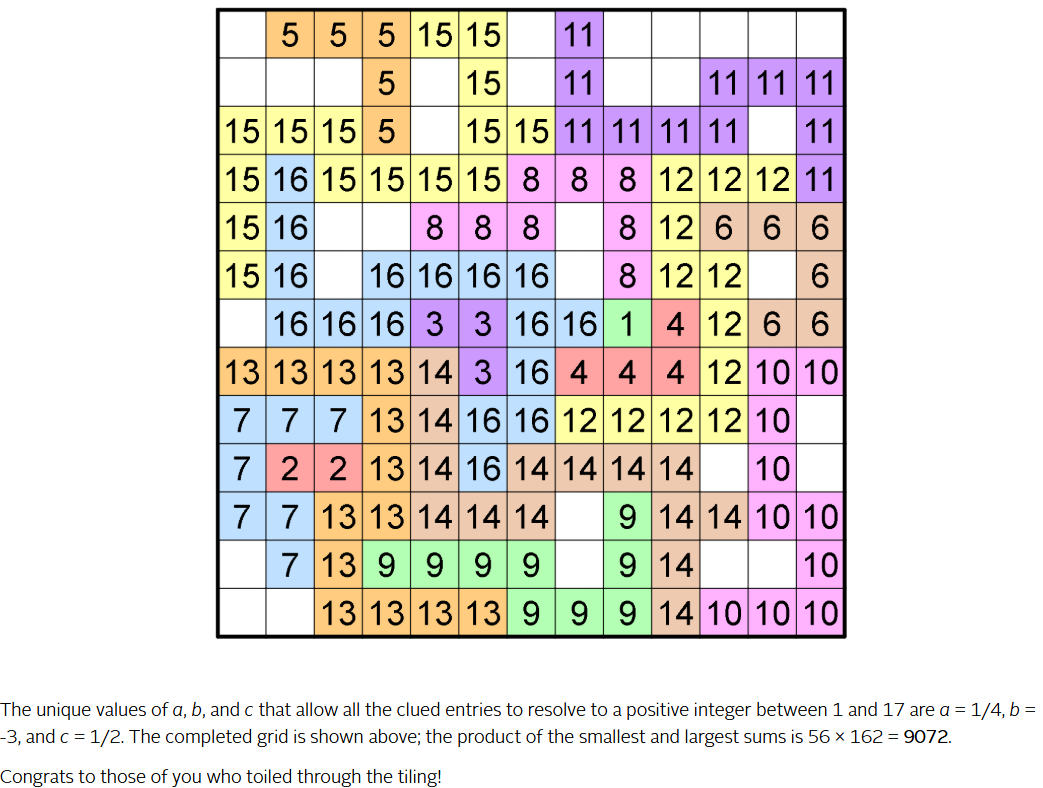